# Stage 0 — Environment and validation of the inference engine

Before touching any science data, check the per-star `cos i` inference and the
Fisher → `cos i` machinery against figures already in the literature:

| Check | Target |
|---|---|
| 1 | Environment + network access |
| 2 | Masuda & Winn (2020) Figure 1, all four panels, analytic vs. MCMC vs. incorrect methods |
| 3 | Bottom-right panel returns the flat prior |
| 4 | Morton & Winn (2014) Figure 2 (divide-and-clip pile-up) |
| 5 | Morton & Winn (2014) Figure 1 (`f_cosI(z|κ)` vs. Monte Carlo) |

The physics lives in `src/`; this notebook only orchestrates and plots.

In [1]:
import sys, platform, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import matplotlib.pyplot as plt
import scipy, emcee, astropy, astroquery, pandas as pd, matplotlib

from src.inclination import (gaussian_likelihood, flat_upper_limit_likelihood,
    posterior_cosi, incorrect_product_rule,
    incorrect_independent_mc, incorrect_divide_and_clip, mcmc_posterior_cosi)
from src.obliquity import f_cosi, sample_cosi_given_kappa, fisher_theta_pdf

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RNG = np.random.default_rng(2014)
COSI = np.linspace(0, 1, 1001)

# one color per method, used in every figure of the project
COL = dict(correct="#2a78d6", mw14="#eb6834",
           product="#c98500", mcmc="#b9b8b0", mc="#6b6a64")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "font.size": 10})

## 1. Environment and network check

In [2]:
print("Python", platform.python_version())
for m in (np, scipy, emcee, astropy, astroquery, pd, matplotlib):
    print(f"{m.__name__:<11} {m.__version__}")

Python 3.10.21
numpy       1.26.4
scipy       1.15.2
emcee       3.1.6
astropy     6.1.7
astroquery  0.4.11
pandas      2.3.3
matplotlib  3.10.9


In [3]:
# Small query to the NASA Exoplanet Archive, cached in data/raw/ (never re-queried).
import urllib.parse, urllib.request
cache = ROOT / "data/raw/stage0_network_check_dr25.csv"
if not cache.exists():
    q = "select top 5 kepid, kepoi_name, koi_disposition, koi_prad from q1_q17_dr25_koi"
    url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?format=csv&query="
           + urllib.parse.quote(q))
    try:
        with urllib.request.urlopen(url, timeout=60) as r:
            cache.write_bytes(r.read())
        print("downloaded ->", cache.relative_to(ROOT))
    except Exception as e:
        print("NETWORK CHECK FAILED:", e)
if cache.exists():
    t = pd.read_csv(cache); print("shape:", t.shape); display(t)

shape: (5, 4)


,kepid,kepoi_name,koi_disposition,koi_prad
0,10811496,K00753.01,FALSE POSITIVE,14.60
1,10848459,K00754.01,FALSE POSITIVE,33.46
2,10854555,K00755.01,CONFIRMED,2.75
3,10872983,K00756.01,CONFIRMED,3.90
4,10872983,K00756.02,CONFIRMED,2.77


## 2. Masuda & Winn (2020) Figure 1

`v = 10 ± 2 km/s` in every panel; the `v sin i` likelihood changes.  Thick blue
is the analytic correct posterior (their Eq. 10); filled gray is an independent
MCMC over `(v, cos i)`. The other curves are the incorrect procedures they
discuss:

* **incorrect Monte Carlo** (gray outline): sample `v` and `v sin i` independently, discard `sin i > 1`
* **product rule** (Eq. 12), mathematically the same as the incorrect Monte Carlo
* **Eq. 18** — the Morton & Winn (2014) marginalization, the one this project corrects

The published figure also shows Eqs. 20 and 21 (Winn et al. 2017; Muñoz & Perets
2018). They are omitted here: their form could not be read reliably from the PDF,
and they play no role in this project.

,panel,max_cdf_diff,n_mcmc
0,vsin i = 9.8 pm 2.0 km/s,0.004887,160000
1,vsin i = 4.0 pm 2.0 km/s,0.006057,160000
2,vsin i < 5 km/s,0.003670,160000
3,vsin i < 30 km/s,0.003439,160000


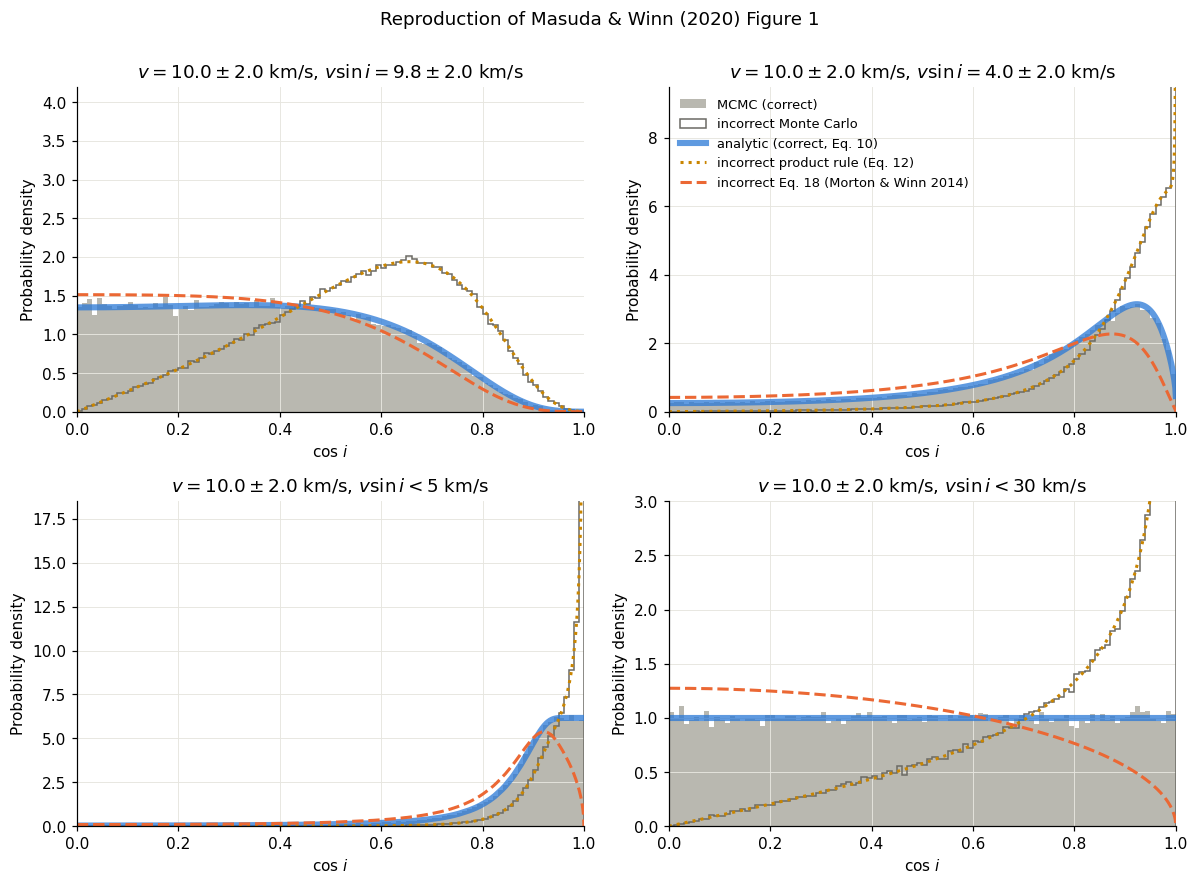

In [4]:
L_v = gaussian_likelihood(10.0, 2.0)
panels = [("$v\\sin i = 9.8 \\pm 2.0$ km/s", gaussian_likelihood(9.8, 2.0),
           lambda n: np.abs(RNG.normal(9.8, 2.0, n))),
          ("$v\\sin i = 4.0 \\pm 2.0$ km/s", gaussian_likelihood(4.0, 2.0),
           lambda n: np.abs(RNG.normal(4.0, 2.0, n))),
          ("$v\\sin i < 5$ km/s", flat_upper_limit_likelihood(5.0),
           lambda n: RNG.uniform(0, 5.0, n)),
          ("$v\\sin i < 30$ km/s", flat_upper_limit_likelihood(30.0),
           lambda n: RNG.uniform(0, 30.0, n))]
ylims = [4.2, 9.5, 18.5, 3.0]
bins = np.linspace(0, 1, 101)
agreement = []

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for k, (ax, (title, L_u, draw_u), ylim) in enumerate(zip(axes.flat, panels, ylims)):
    correct = posterior_cosi(COSI, L_v, L_u, method="correct")
    chain = mcmc_posterior_cosi(L_v, L_u, seed=k)
    n = 400_000
    v_s = RNG.normal(10.0, 2.0, n); v_s = v_s[v_s > 0]
    mc = incorrect_independent_mc(v_s, draw_u(len(v_s)))

    ax.hist(chain, bins, density=True, color=COL["mcmc"], label="MCMC (correct)")
    ax.hist(mc, bins, density=True, histtype="step", color=COL["mc"], lw=1,
            label="incorrect Monte Carlo")
    ax.plot(COSI, correct, color=COL["correct"], lw=4, alpha=0.75, label="analytic (correct, Eq. 10)")
    ax.plot(COSI, incorrect_product_rule(COSI, L_v, L_u), ":", color=COL["product"], label="incorrect product rule (Eq. 12)")
    ax.plot(COSI, posterior_cosi(COSI, L_v, L_u, method="mw14"), "--", color=COL["mw14"], label="incorrect Eq. 18 (Morton & Winn 2014)")
    ax.set(title=f"$v = 10.0 \\pm 2.0$ km/s, {title}", xlabel="cos $i$",
           ylabel="Probability density", xlim=(0, 1), ylim=(0, ylim))

    h, _ = np.histogram(chain, bins, density=True)
    mid = 0.5 * (bins[1:] + bins[:-1])
    cdf = np.cumsum(correct) / np.sum(correct)
    ecdf = np.searchsorted(np.sort(chain), COSI, side="right") / len(chain)
    agreement.append(dict(panel=title.replace("$", "").replace("\\", ""),
                          max_cdf_diff=np.max(np.abs(ecdf - cdf)),
                          n_mcmc=len(chain)))
axes[0, 1].legend(loc="upper left", fontsize=8.5, frameon=False)
fig.suptitle("Reproduction of Masuda & Winn (2020) Figure 1", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "stage0_mw20_fig1.png", bbox_inches="tight")
pd.DataFrame(agreement)

**Analytic vs. MCMC.** The table gives the largest gap between the MCMC
empirical CDF and the analytic CDF in each panel. Anything below ~0.01–0.02 is
agreement within Monte Carlo noise (the MCMC samples are autocorrelated, so this
is a looser check than a nominal KS test).

## 3. Uninformative `v sin i` returns the prior

In [5]:
flat = posterior_cosi(COSI, L_v, flat_upper_limit_likelihood(30.0), method="correct")
mw14_flat = posterior_cosi(COSI, L_v, flat_upper_limit_likelihood(30.0), method="mw14")
print(f"correct method: max |p(cos i) - 1| = {np.max(np.abs(flat - 1)):.2e}")
print(f"MW14 method:    p(0) = {mw14_flat[0]:.3f}, p(0.9) = {mw14_flat[900]:.3f}"
      "   (analytically ∝ sin i, i.e. 4/π ≈ 1.273 at cos i = 0)")
assert np.max(np.abs(flat - 1)) < 1e-3, "flat-prior test FAILED: stop here"

correct method: max |p(cos i) - 1| = 5.55e-16
MW14 method:    p(0) = 1.273, p(0.9) = 0.555   (analytically ∝ sin i, i.e. 4/π ≈ 1.273 at cos i = 0)


The correct method returns the prior to numerical precision. The Morton &
Winn marginalization does **not**: when `v sin i` carries no information it
still returns a posterior ∝ `sin i`, which favours alignment (small `cos i`)
whatever the data say. This is the bias the rest of the project quantifies.

## 4. Morton & Winn (2014) Figure 2

`V sin I = V = 10 ± 0.5 km/s`. Their figure labels their Eq. 13 curve the
"true posterior"; Masuda & Winn later showed Eq. 13 is itself incorrect. Both
curves are shown: the orange dashed curve should reproduce the published thick
curve, the blue curve is the corrected version.

pile-up at cos I = 0: 49.9%  (paper: ~50%)
Eq. 13 density at cos I = 0, 0.2, 0.4, 0.6: [2.63 2.5  1.18 0.02]  (paper: ~2.6 flat to 0.2, ~0 by 0.6)


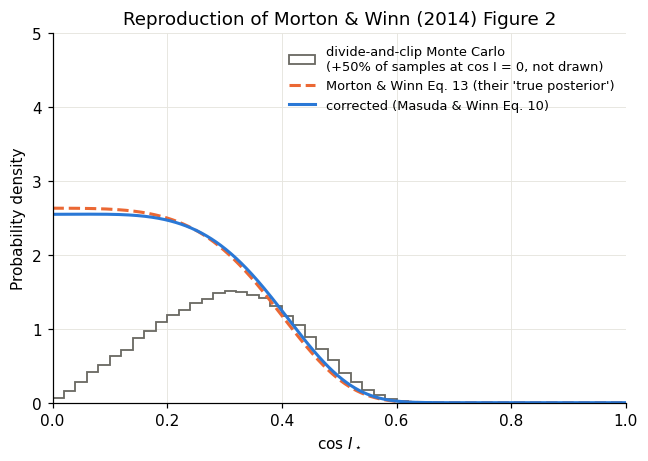

In [6]:
L = gaussian_likelihood(10.0, 0.5)
n = 200_000
clip = incorrect_divide_and_clip(RNG.normal(10, 0.5, n), RNG.normal(10, 0.5, n))
frac0 = np.mean(clip == 0)

fig, ax = plt.subplots(figsize=(6, 4.3))
ax.hist(clip[clip > 0], bins=np.linspace(0, 1, 51), weights=np.full((clip > 0).sum(), 50 / n),
        histtype="step", color=COL["mc"], lw=1.2,
        label=f"divide-and-clip Monte Carlo\n(+{frac0:.0%} of samples at cos I = 0, not drawn)")
ax.plot(COSI, posterior_cosi(COSI, L, L, method="mw14"), "--", color=COL["mw14"],
        label="Morton & Winn Eq. 13 (their 'true posterior')")
ax.plot(COSI, posterior_cosi(COSI, L, L, method="correct"), color=COL["correct"],
        label="corrected (Masuda & Winn Eq. 10)")
ax.set(xlabel="cos $I_\\star$", ylabel="Probability density", xlim=(0, 1), ylim=(0, 5),
       title="Reproduction of Morton & Winn (2014) Figure 2")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "stage0_mw14_fig2.png", bbox_inches="tight")
mw = posterior_cosi(COSI, L, L, method="mw14")
print(f"pile-up at cos I = 0: {frac0:.1%}  (paper: ~50%)")
print(f"Eq. 13 density at cos I = 0, 0.2, 0.4, 0.6: {mw[[0,200,400,600]].round(2)}  (paper: ~2.6 flat to 0.2, ~0 by 0.6)")

## 5. Morton & Winn (2014) Figure 1: `f_cosI(z|κ)` vs. direct Monte Carlo

,kappa,max_rel_diff_vs_MC
0,1,0.017585
1,5,0.011832
2,20,0.003789
3,100,0.007156


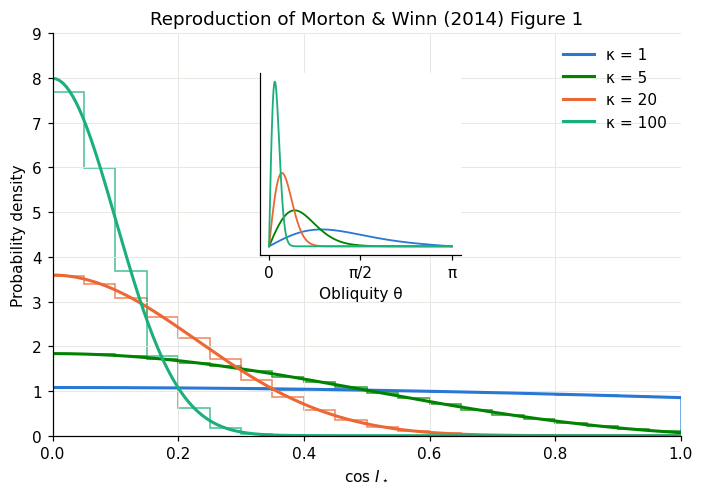

In [7]:
kappas = [1, 5, 20, 100]
kcol = ["#2a78d6", "#008300", "#eb6834", "#1baf7a"]
fig, ax = plt.subplots(figsize=(6.5, 4.6))
z = np.linspace(0, 1, 401)
rows = []
for k, c in zip(kappas, kcol):
    s = sample_cosi_given_kappa(k, 200_000, RNG)
    h, e = np.histogram(s, 20, (0, 1), density=True)
    ax.stairs(h, e, color=c, lw=1, alpha=0.8)
    fz = f_cosi(z, k)
    ax.plot(z, fz, color=c, label=f"κ = {k}")
    mid = 0.5 * (e[1:] + e[:-1])
    rows.append(dict(kappa=k, max_rel_diff_vs_MC=np.max(np.abs(h - f_cosi(mid, k))) / fz.max()))
ax.set(xlabel="cos $I_\\star$", ylabel="Probability density", xlim=(0, 1), ylim=(0, 9),
       title="Reproduction of Morton & Winn (2014) Figure 1")
ax.legend(frameon=False)
ins = ax.inset_axes([0.33, 0.45, 0.32, 0.45])
th = np.linspace(0, np.pi, 400)
for k, c in zip(kappas, kcol):
    ins.plot(th, fisher_theta_pdf(th, k), color=c, lw=1.2)
ins.set(xticks=[0, np.pi/2, np.pi], xticklabels=["0", "π/2", "π"], yticks=[],
        xlabel="Obliquity θ"); ins.grid(False)
fig.tight_layout(); fig.savefig(FIG / "stage0_mw14_fig1.png", bbox_inches="tight")
pd.DataFrame(rows)

(20 bins for the histograms, as in the paper; finer bins sharpen the κ = 100 peak, whose
analytic value at 0 is ≈ 8.)

### Is the residual between `f_cosI` and Monte Carlo random or systematic?

The figure above shows up to ~2% differences. Test with 2 × 10⁶ samples per κ,
four independent seeds, comparing histogram counts to (a) `f_cosI` at the bin
midpoint, as the figure does, and (b) `f_cosI` integrated over each bin, which is the
correct expectation. Only bins expecting > 20 counts enter χ².

In [8]:
from scipy import integrate
N, edges = 2_000_000, np.linspace(0, 1, 41)
mid = 0.5 * (edges[1:] + edges[:-1])
rows = []
for k in [1, 5, 20, 100]:
    binint = np.array([integrate.quad(lambda z: f_cosi(z, k), a, b, limit=100)[0]
                       for a, b in zip(edges[:-1], edges[1:])])
    counts = [np.histogram(sample_cosi_given_kappa(k, N, np.random.default_rng(s)), edges)[0]
              for s in range(4)]
    for label, pred in [("bin midpoint", f_cosi(mid, k) / 40), ("bin-integrated", binint)]:
        exp = N * pred; use = exp > 20
        z = np.array([(c[use] - exp[use]) / np.sqrt(exp[use]) for c in counts])
        rows.append({"kappa": k, "expectation": label, "bins used": use.sum(),
                     "chi2/dof per seed": np.round((z**2).mean(axis=1), 2),
                     "mean signed z": round(z.mean(), 3),
                     "max |frac. resid.|": round(np.max(np.abs(np.array(counts)[:, use] - exp[use]) / exp[use]), 4)})
pd.DataFrame(rows)

,kappa,expectation,bins used,chi2/dof per seed,mean signed z,max |frac. resid.|
0,1,bin midpoint,40,"[1.08, 0.83, 0.59, 1.05]",-0.004,0.0130
1,1,bin-integrated,40,"[1.08, 0.83, 0.59, 1.05]",-0.001,0.0130
2,5,bin midpoint,40,"[0.72, 1.06, 1.09, 0.79]",0.005,0.0299
3,5,bin-integrated,40,"[0.71, 1.05, 1.09, 0.79]",-0.003,0.0313
4,20,bin midpoint,34,"[0.86, 0.94, 0.66, 0.83]",0.078,0.3232
5,20,bin-integrated,34,"[0.8, 0.88, 0.68, 0.84]",-0.030,0.3360
6,100,bin midpoint,17,"[2.38, 3.05, 1.92, 2.07]",0.602,0.2436
7,100,bin-integrated,17,"[0.6, 1.31, 0.81, 0.8]",-0.064,0.2795


**Result: the discrepancy is random.** Against the bin-integrated expectation,
χ²/dof scatters around 1 for every seed and every κ, and the mean signed
residual is consistent with zero, so there is no κ dependence. The ~2% seen in
the figure is Poisson noise from 2 × 10⁵ samples in 20 bins. The only
systematic effect is in the *midpoint* comparison at κ = 100: a positive mean
residual from the curvature of `f_cosI` across a bin. It belongs to that
comparison, not to `f_cosI`, and disappears with the bin-integrated expectation.

### Normalization: ∫₀¹ f_cosI(z|κ) dz = 1 to 10⁻⁶ across the κ grid

In [9]:
kgrid = np.concatenate([[0.0], np.geomspace(1e-3, 1e4, 36)])
norms = []
for k in kgrid:
    pts = [min(0.99, s / np.sqrt(max(k, 1.0))) for s in (1, 3, 10)]
    norms.append(integrate.quad(lambda z: f_cosi(z, k), 0, 1, points=pts, limit=200)[0])
dev = np.abs(np.array(norms) - 1)
print(f"{len(kgrid)} kappa values in [0, 1e4]; max |integral - 1| = {dev.max():.2e} at kappa = {kgrid[dev.argmax()]:.3g}")
assert dev.max() < 1e-6, "normalization FAILED"

37 kappa values in [0, 1e4]; max |integral - 1| = 3.60e-13 at kappa = 3.98e+03


## Unit tests

The same checks, as an automated suite (`tests/test_stage0.py`).

In [10]:
import subprocess
r = subprocess.run([sys.executable, str(ROOT / "tests/run_tests.py")], capture_output=True, text=True)
print(r.stdout[-3000:], r.stderr[-2000:])
assert r.returncode == 0, "TEST FAILURES: Stage 0 does not pass"

PASS  test_stage0.py::test_f_cosi_endpoint_limit  (0.0s)
PASS  test_stage0.py::test_f_cosi_isotropic_limit  (0.0s)
PASS  test_stage0.py::test_f_cosi_matches_monte_carlo  (1.4s)
PASS  test_stage0.py::test_f_cosi_normalized  (0.4s)
PASS  test_stage0.py::test_flat_prior_recovered_for_uninformative_vsini  (1.4s)
PASS  test_stage0.py::test_kappa_over_sinh_does_not_overflow  (0.0s)
PASS  test_stage0.py::test_mcmc_agrees_with_analytic_all_panels  (6.6s)
PASS  test_stage0.py::test_method_must_be_explicit  (0.0s)
PASS  test_stage0.py::test_mw14_bias_direction  (0.9s)
PASS  test_stage0.py::test_mw14_figure2  (0.3s)
PASS  test_stage0.py::test_values_read_off_mw20_figure1_top_left  (3.9s)
PASS  test_stage1_inputs.py::test_double_correction_is_caught  (0.0s)
PASS  test_stage1_inputs.py::test_multiplicity_mapping  (0.0s)
PASS  test_stage1_inputs.py::test_mw14_is_sini_times_correct  (0.1s)
PASS  test_stage1_inputs.py::test_mw14_vspace_equals_uspace  (0.0s)
PASS  test_stage1_inputs.py::test_p_rot_floo